# SignSetu - Landmark Exploratory Data Analysis

Analysis of normalized 126-D hand landmark vectors from `ml/data/landmarks.csv` (public dataset) and `ml/data/own_samples.csv` (webcam recordings).

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid")

ML_DIR = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd() / "ml"
DATA_DIR = ML_DIR / "data"
FIG_DIR = ML_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_COLS = [f"f{i}" for i in range(126)]

public_path = DATA_DIR / "landmarks.csv"
own_path = DATA_DIR / "own_samples.csv"

public_raw = pd.read_csv(public_path) if public_path.exists() else pd.DataFrame()
own_raw = pd.read_csv(own_path) if own_path.exists() else pd.DataFrame()

if not public_raw.empty:
    public_raw["source"] = "public"
if not own_raw.empty:
    own_raw["source"] = "own"

public_df = public_raw[public_raw["n_hands"] > 0].copy() if not public_raw.empty else pd.DataFrame()
own_df = own_raw[own_raw["n_hands"] > 0].copy() if not own_raw.empty else pd.DataFrame()

print(f"Public raw rows: {len(public_raw)} | Detected (n_hands > 0): {len(public_df)}")
print(f"Own raw rows:    {len(own_raw)} | Detected (n_hands > 0): {len(own_df)}")

Public raw rows: 702 | Detected (n_hands > 0): 478
Own raw rows:    0 | Detected (n_hands > 0): 0


## 1. Samples per Class and Imbalance Check

Public imbalance ratio (max/min): 29/10 = 2.90x
Own dataset has 0 detected samples; skipping own class-count plot.


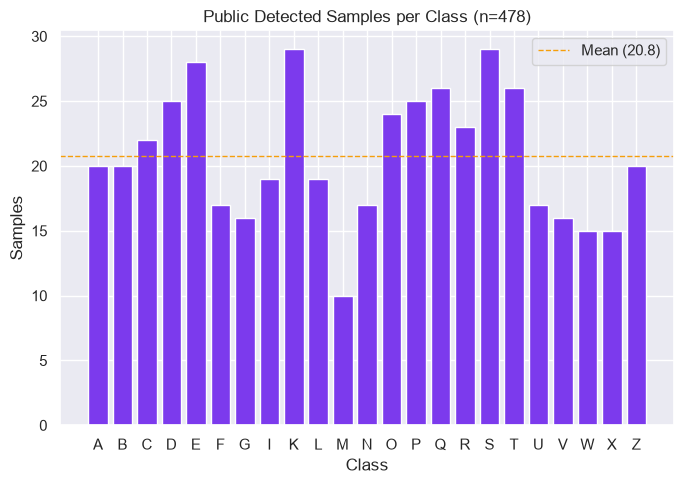

In [2]:
has_own = len(own_df) > 0
n_panels = 2 if has_own else 1
fig, axes = plt.subplots(1, n_panels, figsize=(7 * n_panels, 5), squeeze=False)

pub_counts = public_df["label"].value_counts().sort_index()
axes[0, 0].bar(pub_counts.index, pub_counts.values, color="#7c3aed")
axes[0, 0].set_title(f"Public Detected Samples per Class (n={len(public_df)})")
axes[0, 0].set_xlabel("Class")
axes[0, 0].set_ylabel("Samples")
axes[0, 0].axhline(pub_counts.mean(), color="#f59e0b", linestyle="--", linewidth=1, label=f"Mean ({pub_counts.mean():.1f})")
axes[0, 0].legend()

print(
    f"Public imbalance ratio (max/min): {pub_counts.max()}/{pub_counts.min()} = "
    f"{pub_counts.max() / pub_counts.min():.2f}x"
)

if has_own:
    own_counts = own_df["label"].value_counts().sort_index()
    axes[0, 1].bar(own_counts.index, own_counts.values, color="#10b981")
    axes[0, 1].set_title(f"Own Webcam Samples per Class (n={len(own_df)})")
    axes[0, 1].set_xlabel("Class")
    axes[0, 1].set_ylabel("Samples")
    if own_counts.min() > 0:
        print(
            f"Own imbalance ratio (max/min): {own_counts.max()}/{own_counts.min()} = "
            f"{own_counts.max() / own_counts.min():.2f}x"
        )
else:
    print("Own dataset has 0 detected samples; skipping own class-count plot.")

plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150)
plt.show()

Public detected counts range from 10 (`M`) to 29 (`S`), a ~2.9x class imbalance driven largely by MediaPipe detection drop-offs on occluded signs rather than raw image counts alone.

## 2. Share of 1-Hand vs 2-Hand Samples per Class

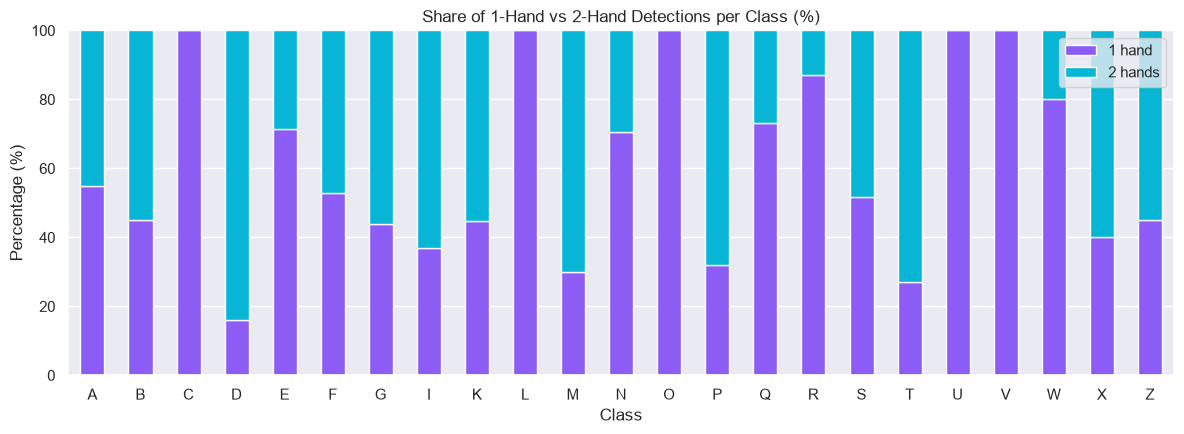

In [3]:
combined_df = pd.concat([d for d in [public_df, own_df] if not d.empty], ignore_index=True)
hand_ct = pd.crosstab(combined_df["label"], combined_df["n_hands"]).reindex(columns=[1, 2], fill_value=0)
hand_share = hand_ct.div(hand_ct.sum(axis=1), axis=0) * 100.0

ax = hand_share.plot(kind="bar", stacked=True, figsize=(12, 4.5), color=["#8b5cf6", "#06b6d4"])
ax.set_title("Share of 1-Hand vs 2-Hand Detections per Class (%)")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage (%)")
ax.legend(["1 hand", "2 hands"], loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "hand_count_share.png", dpi=150)
plt.show()

Classes `C`, `L`, `O`, `U`, `V` are purely 1-hand detections, while `D`, `P`, `T` are predominantly 2-hand signs. Several nominally 2-hand signs (`A`, `B`, `E`, `M`, `N`) show mixed 1-hand/2-hand detections when one hand is partially occluded.

## 3. Mean Hand Skeletons per Class

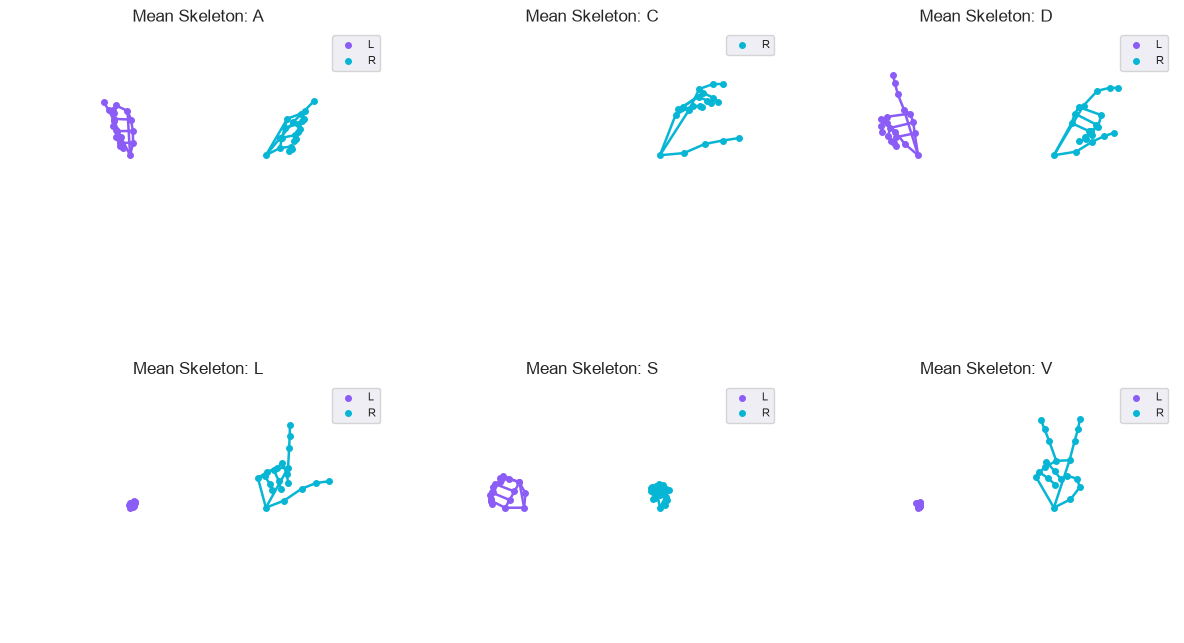

In [4]:
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17),
]

sample_classes = [c for c in ["A", "C", "D", "L", "S", "V"] if c in combined_df["label"].unique()]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, cls in zip(axes.flat, sample_classes):
    mean_vec = combined_df.loc[combined_df["label"] == cls, FEATURE_COLS].mean().to_numpy()
    left = mean_vec[:63].reshape(21, 3)
    right = mean_vec[63:].reshape(21, 3)

    for pts, color, offset_x, name in [(left, "#8b5cf6", -0.65, "L"), (right, "#06b6d4", 0.65, "R")]:
        if np.linalg.norm(pts) < 1e-3:
            continue
        xs = pts[:, 0] + offset_x
        ys = -pts[:, 1]
        for a, b in HAND_CONNECTIONS:
            ax.plot([xs[a], xs[b]], [ys[a], ys[b]], color=color, linewidth=1.8)
        ax.scatter(xs, ys, color=color, s=16, label=name)

    ax.set_title(f"Mean Skeleton: {cls}")
    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "mean_skeletons.png", dpi=150)
plt.show()

## 4. PCA and UMAP Embeddings (Class Separation & Domain Gap)

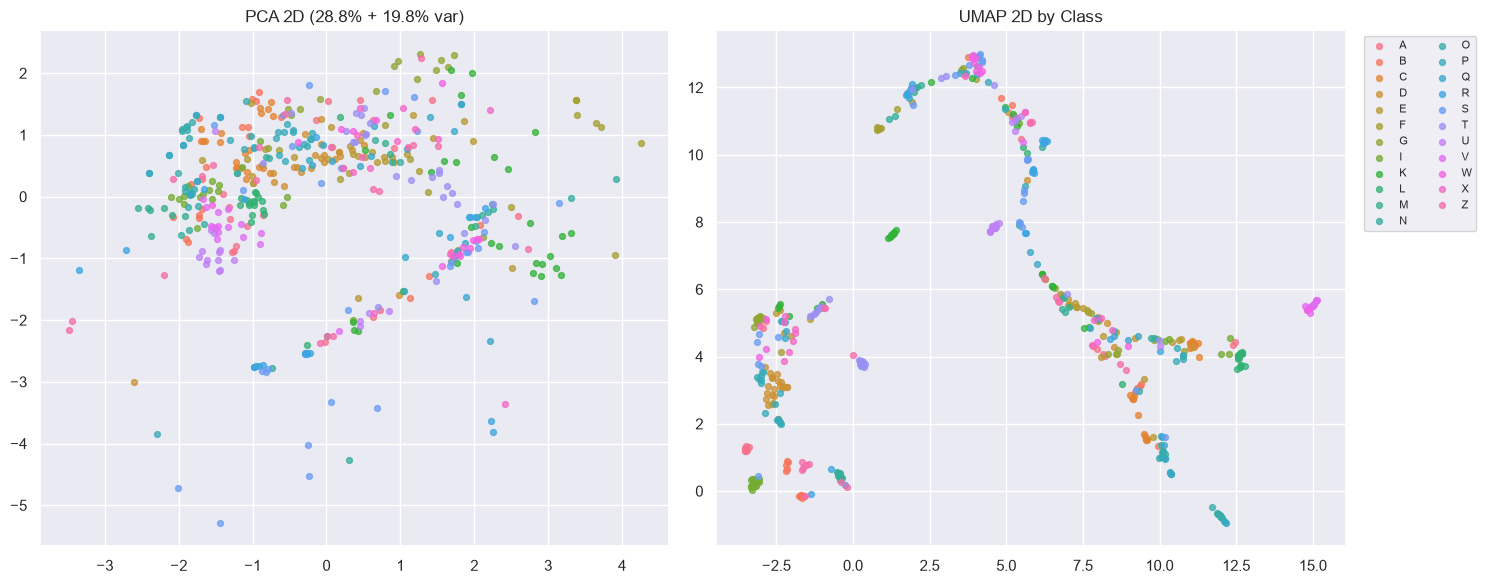

In [5]:
X = combined_df[FEATURE_COLS].to_numpy(dtype=np.float32)
y = combined_df["label"].to_numpy()
sources = combined_df["source"].to_numpy()

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.15, random_state=42)
X_umap = reducer.fit_transform(X)

classes_sorted = sorted(combined_df["label"].unique())
palette = sns.color_palette("husl", len(classes_sorted))
color_map = dict(zip(classes_sorted, palette))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for cls in classes_sorted:
    mask = y == cls
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=18, alpha=0.75, color=color_map[cls], label=cls)
    axes[1].scatter(X_umap[mask, 0], X_umap[mask, 1], s=18, alpha=0.75, color=color_map[cls], label=cls)

axes[0].set_title(
    f"PCA 2D ({pca.explained_variance_ratio_[0]*100:.1f}% + {pca.explained_variance_ratio_[1]*100:.1f}% var)"
)
axes[1].set_title("UMAP 2D by Class")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "pca_umap_classes.png", dpi=150)
plt.show()

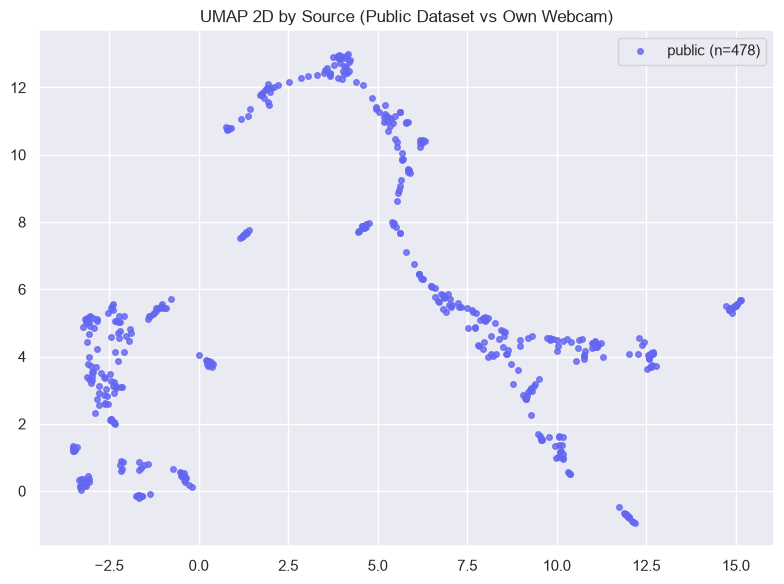

Closest class pairs in UMAP space (highest overlap risk):
  E <-> Q: dist=0.43
  G <-> T: dist=0.50
  R <-> U: dist=0.60
  F <-> N: dist=0.62
  F <-> R: dist=0.62
  G <-> X: dist=0.63


In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
for src, col in [("public", "#6366f1"), ("own", "#ef4444")]:
    mask = sources == src
    if mask.sum() > 0:
        ax.scatter(X_umap[mask, 0], X_umap[mask, 1], s=25 if src == "own" else 16, alpha=0.8, color=col, label=f"{src} (n={mask.sum()})")

ax.set_title("UMAP 2D by Source (Public Dataset vs Own Webcam)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "umap_domain_gap.png", dpi=150)
plt.show()

centroids = pd.DataFrame(X_umap, columns=["u1", "u2"]).assign(label=y).groupby("label").mean()
dists = np.linalg.norm(centroids.to_numpy()[:, None, :] - centroids.to_numpy()[None, :, :], axis=-1)
np.fill_diagonal(dists, np.inf)
pairs = []
lbls = centroids.index.to_list()
for i in range(len(lbls)):
    for j in range(i + 1, len(lbls)):
        pairs.append((dists[i, j], lbls[i], lbls[j]))
pairs.sort()
print("Closest class pairs in UMAP space (highest overlap risk):")
for d, a, b in pairs[:6]:
    print(f"  {a} <-> {b}: dist={d:.2f}")

PCA separates 1-hand vs 2-hand clusters along PC1, while UMAP forms tighter per-class islands. Classes with similar finger curls or shared 1-hand/2-hand structure sit closest in UMAP space (see printed nearest pairs above). Once `own_samples.csv` has recordings across classes, the source-coloured UMAP directly highlights any domain shift between static dataset photos and live webcam framing.

## 5. Random Forest Feature Importance by Landmark

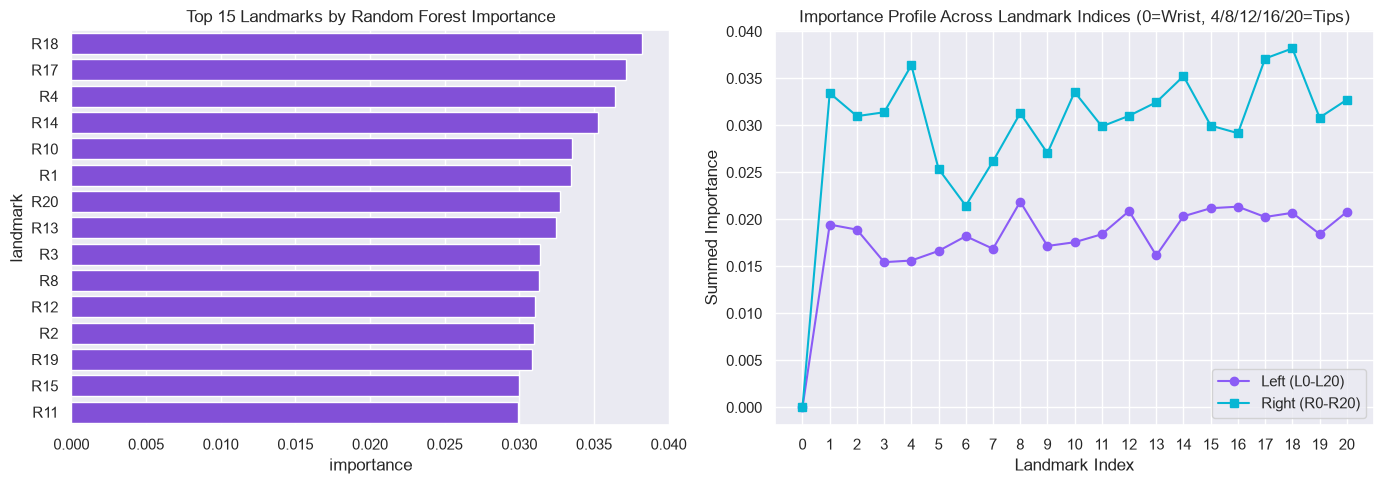

In [7]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X, y)

imp = rf.feature_importances_.reshape(42, 3).sum(axis=1)
lm_names = [f"L{i}" for i in range(21)] + [f"R{i}" for i in range(21)]
imp_df = pd.DataFrame({"landmark": lm_names, "importance": imp})
top_lm = imp_df.sort_values("importance", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top_lm, x="importance", y="landmark", ax=axes[0], color="#7c3aed")
axes[0].set_title("Top 15 Landmarks by Random Forest Importance")

per_idx = imp.reshape(2, 21)
x_idx = np.arange(21)
axes[1].plot(x_idx, per_idx[0], marker="o", label="Left (L0-L20)", color="#8b5cf6")
axes[1].plot(x_idx, per_idx[1], marker="s", label="Right (R0-R20)", color="#06b6d4")
axes[1].set_title("Importance Profile Across Landmark Indices (0=Wrist, 4/8/12/16/20=Tips)")
axes[1].set_xlabel("Landmark Index")
axes[1].set_ylabel("Summed Importance")
axes[1].set_xticks(x_idx)
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "rf_landmark_importance.png", dpi=150)
plt.show()

## 6. Outlier Check per Class (Distance from Centroid)

label  samples  mean_dist  max_dist  outliers_gt_2std
    A       20      2.405     4.319                 1
    B       20      2.252     3.929                 1
    C       22      0.990     1.532                 1
    D       25      1.284     4.762                 1
    E       28      1.912     4.072                 1
    F       17      2.274     3.546                 1
    G       16      1.839     3.109                 1
    I       19      1.569     2.880                 1
    K       29      2.195     3.280                 0
    L       19      0.989     3.207                 3
    M       10      2.151     5.034                 1
    N       17      3.090     4.548                 0
    O       24      0.908     1.779                 1
    P       25      1.639     5.256                 1
    Q       26      2.590     4.090                 1
    R       23      2.972     4.154                 0
    S       29      3.403     5.401                 2
    T       26      2.409   

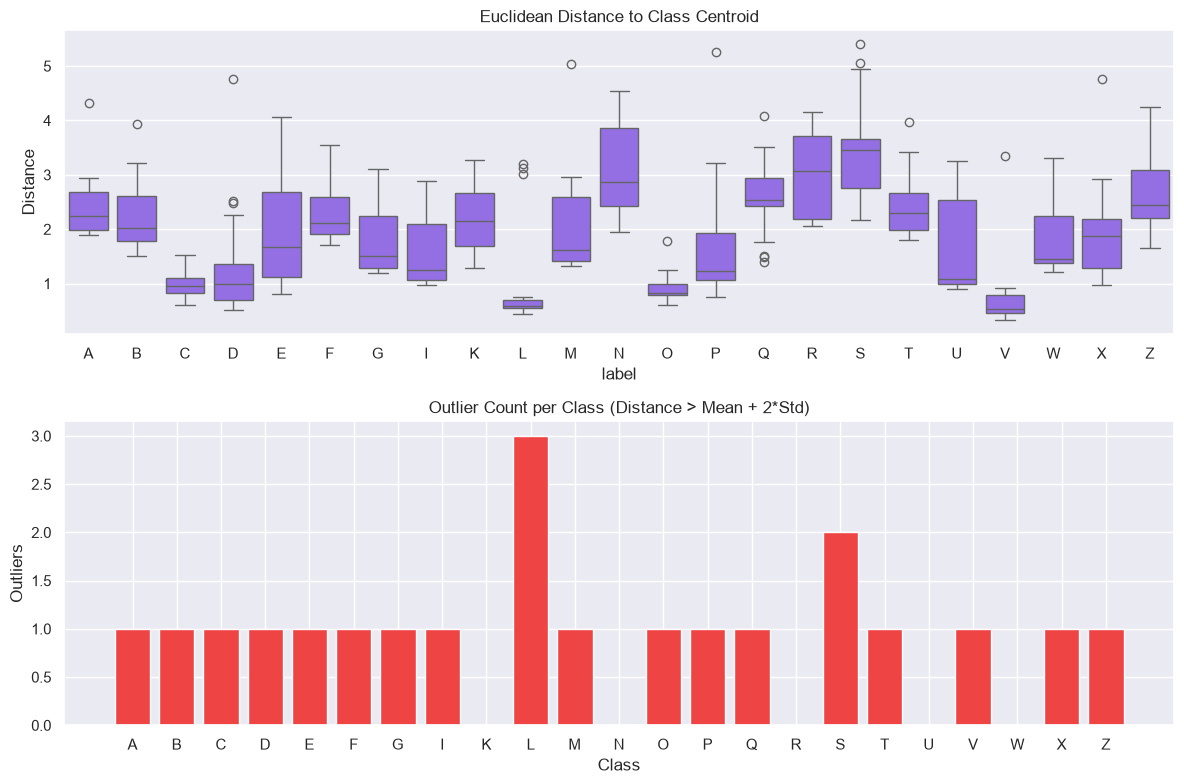

In [8]:
outlier_rows = []
all_dists = []

for cls, grp in combined_df.groupby("label", sort=True):
    feats = grp[FEATURE_COLS].to_numpy(dtype=np.float32)
    centroid = feats.mean(axis=0)
    dists = np.linalg.norm(feats - centroid, axis=1)
    thresh = dists.mean() + 2.0 * dists.std()
    n_out = int((dists > thresh).sum()) if len(dists) >= 3 else 0
    outlier_rows.append(
        {
            "label": cls,
            "samples": len(dists),
            "mean_dist": round(float(dists.mean()), 3),
            "max_dist": round(float(dists.max()), 3),
            "outliers_gt_2std": n_out,
        }
    )
    for d in dists:
        all_dists.append({"label": cls, "dist": float(d)})

outlier_df = pd.DataFrame(outlier_rows)
dist_df = pd.DataFrame(all_dists)
print(outlier_df.to_string(index=False))
print(f"\nTotal outliers (> mean + 2*std): {outlier_df['outliers_gt_2std'].sum()} / {len(combined_df)}")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
sns.boxplot(data=dist_df, x="label", y="dist", ax=axes[0], color="#8b5cf6")
axes[0].set_title("Euclidean Distance to Class Centroid")
axes[0].set_ylabel("Distance")

axes[1].bar(outlier_df["label"], outlier_df["outliers_gt_2std"], color="#ef4444")
axes[1].set_title("Outlier Count per Class (Distance > Mean + 2*Std)")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Outliers")

plt.tight_layout()
plt.savefig(FIG_DIR / "class_outliers.png", dpi=150)
plt.show()